In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import OneHotEncoder

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    ExtraTreesRegressor
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully")

Libraries imported successfully


In [4]:
# Load dataset
df = pd.read_csv("Insurance.csv")

# Display first five records
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [6]:
df.shape

(1338, 7)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [8]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [9]:
df.describe(include='object')

/var/folders/yh/48l9slt11bsgwmj8bs9t6_zr0000gn/T/ipykernel_99223/87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


In [10]:
for col in df.columns:
    print(col, ":", df[col].nunique())

age : 47
sex : 2
bmi : 548
children : 6
smoker : 2
region : 4
charges : 1337


In [11]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1338
Number of columns: 7


In [12]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'],
      dtype='str')

In [13]:
df.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

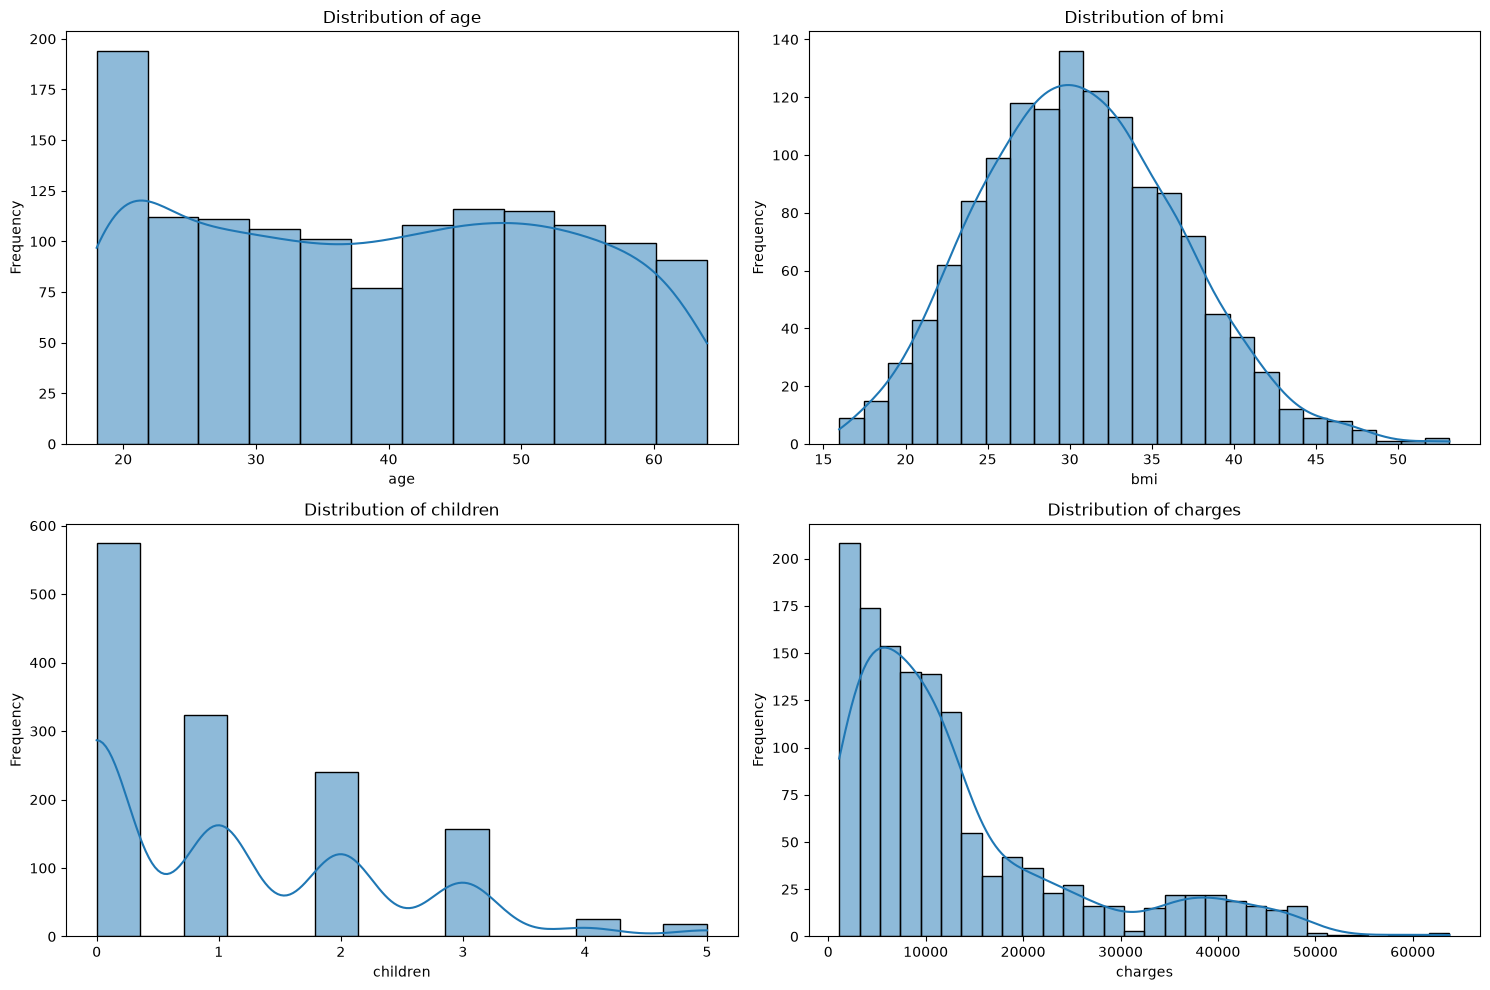

In [14]:
# Select numerical columns
num_cols = df.select_dtypes(include=np.number).columns

# Plot histograms
plt.figure(figsize=(15, 10))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

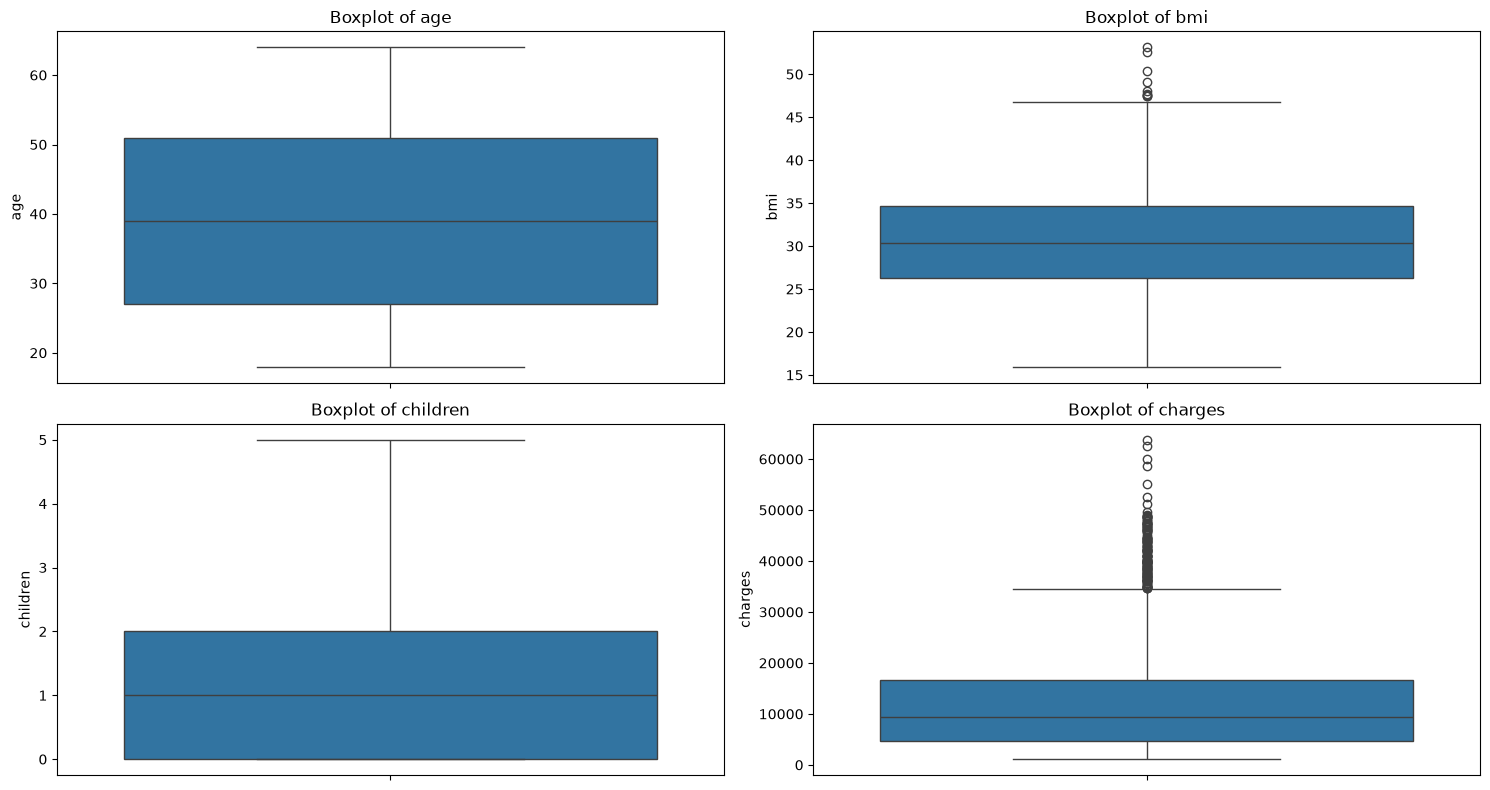

In [15]:
plt.figure(figsize=(15, 8))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [16]:
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    print("\nColumn:", col)
    print(df[col].value_counts())


Column: sex
sex
male      676
female    662
Name: count, dtype: int64

Column: smoker
smoker
no     1064
yes     274
Name: count, dtype: int64

Column: region
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


/var/folders/yh/48l9slt11bsgwmj8bs9t6_zr0000gn/T/ipykernel_99223/4067919808.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


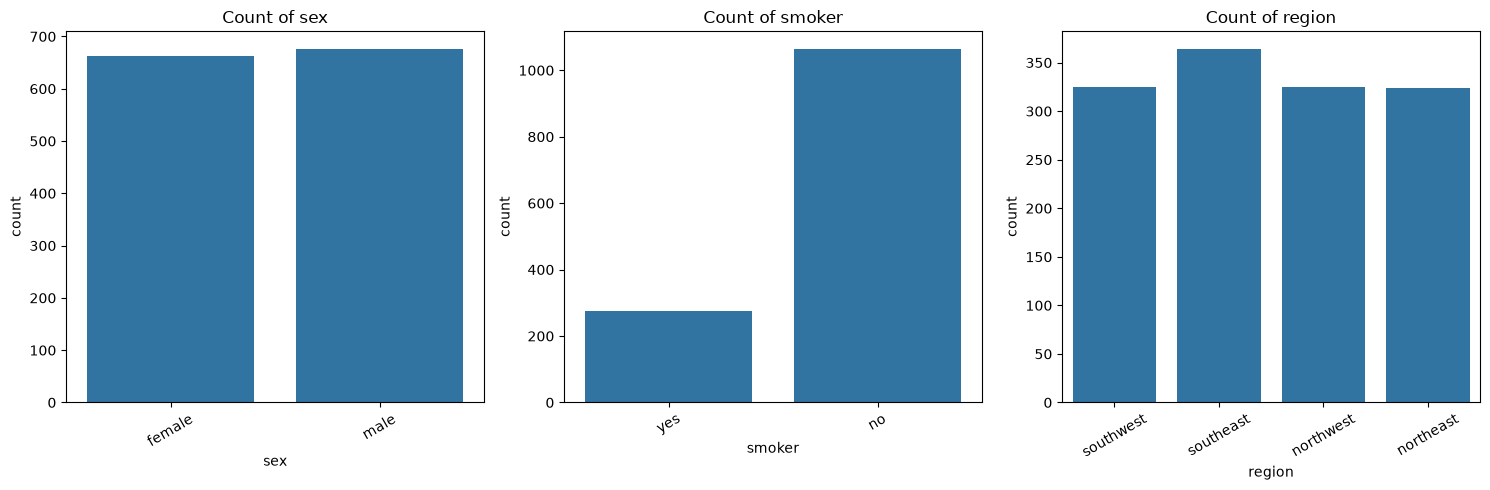

In [17]:
plt.figure(figsize=(15, 5))

for i, col in enumerate(cat_cols, 1):
    plt.subplot(1, 3, i)
    sns.countplot(data=df, x=col)
    plt.title(f'Count of {col}')
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

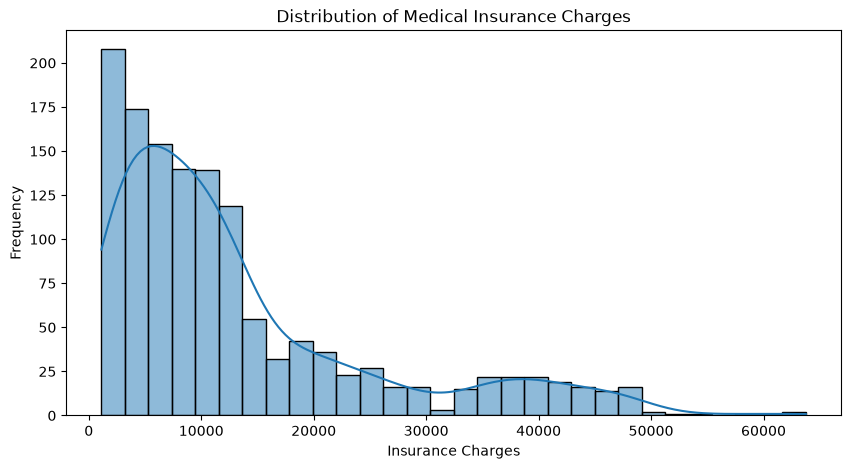

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(df['charges'], kde=True)

plt.title('Distribution of Medical Insurance Charges')
plt.xlabel('Insurance Charges')
plt.ylabel('Frequency')

plt.show()

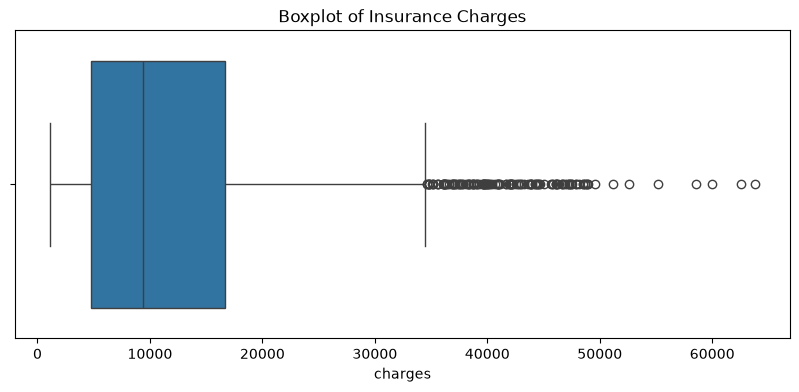

In [19]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['charges'])

plt.title('Boxplot of Insurance Charges')

plt.show()

In [20]:
print("Skewness of Charges:", df['charges'].skew())

Skewness of Charges: 1.5158796580240388


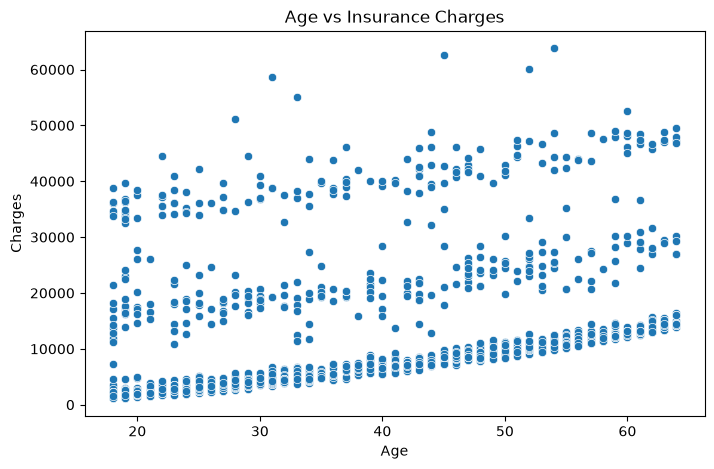

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='age',
    y='charges'
)

plt.title('Age vs Insurance Charges')
plt.xlabel('Age')
plt.ylabel('Charges')

plt.show()

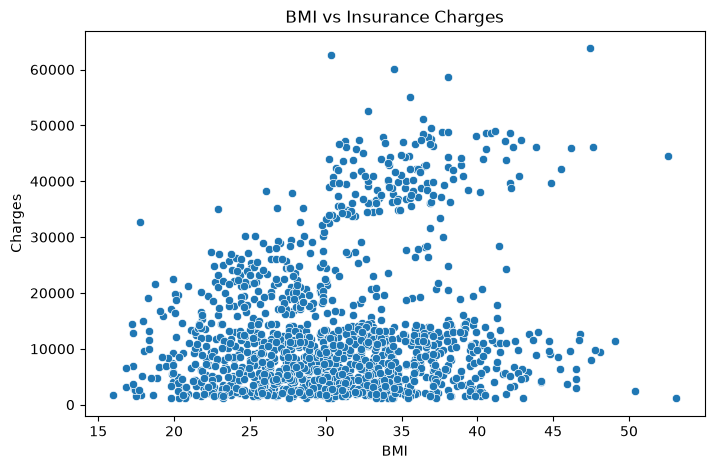

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='bmi',
    y='charges'
)

plt.title('BMI vs Insurance Charges')
plt.xlabel('BMI')
plt.ylabel('Charges')

plt.show()

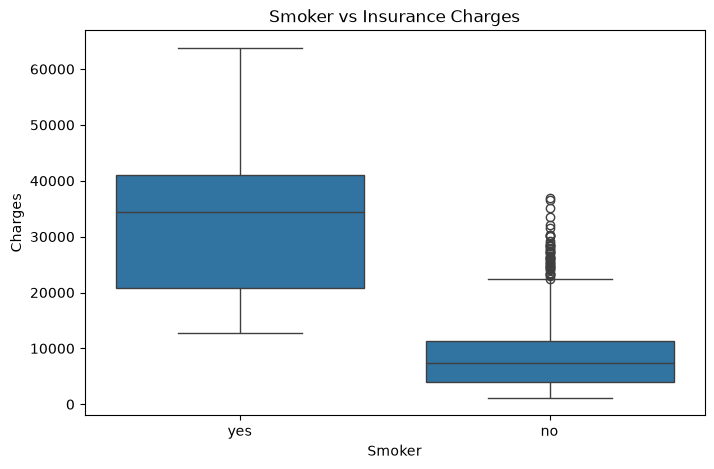

In [23]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='smoker',
    y='charges'
)

plt.title('Smoker vs Insurance Charges')
plt.xlabel('Smoker')
plt.ylabel('Charges')

plt.show()

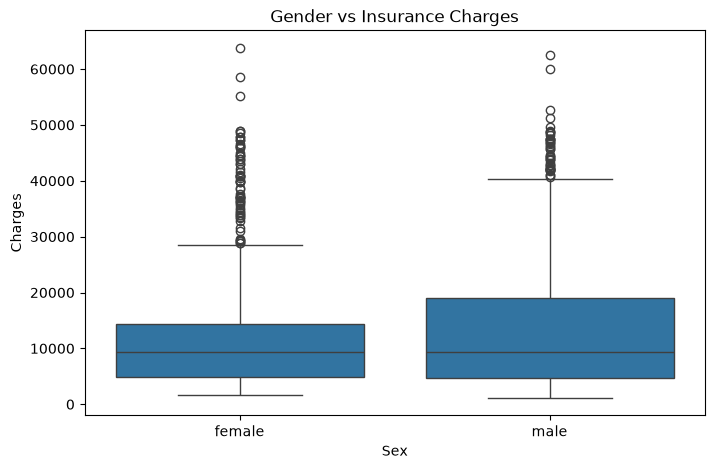

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='sex',
    y='charges'
)

plt.title('Gender vs Insurance Charges')
plt.xlabel('Sex')
plt.ylabel('Charges')

plt.show()

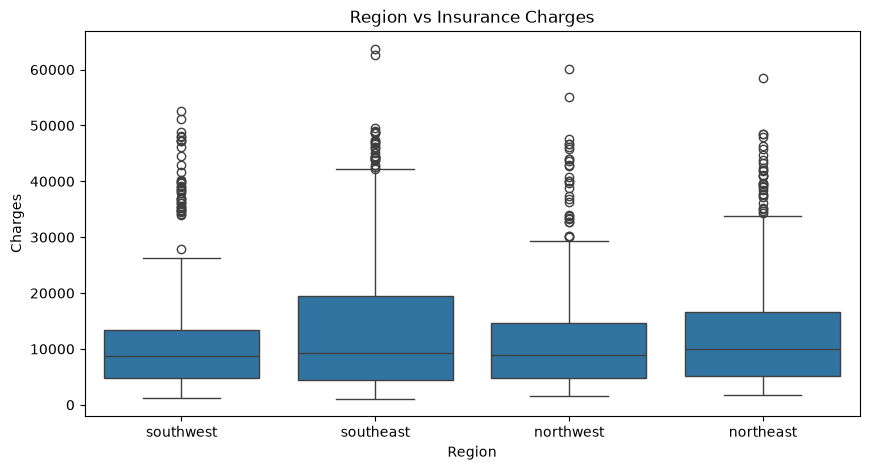

In [25]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='region',
    y='charges'
)

plt.title('Region vs Insurance Charges')
plt.xlabel('Region')
plt.ylabel('Charges')

plt.show()

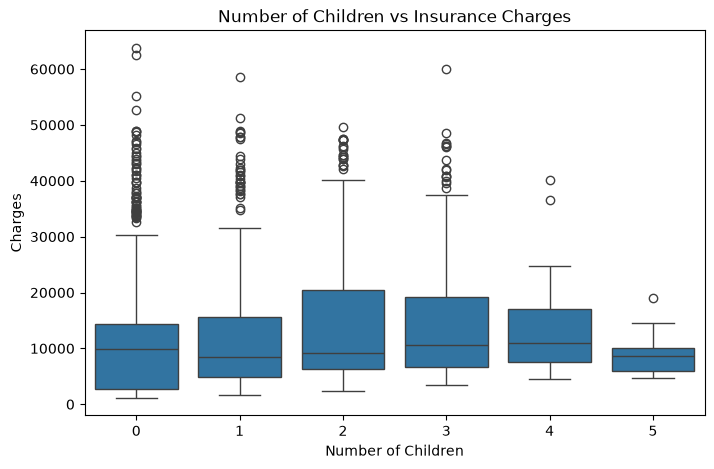

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='children',
    y='charges'
)

plt.title('Number of Children vs Insurance Charges')
plt.xlabel('Number of Children')
plt.ylabel('Charges')

plt.show()

In [27]:
corr = df.select_dtypes(include=np.number).corr()

corr

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


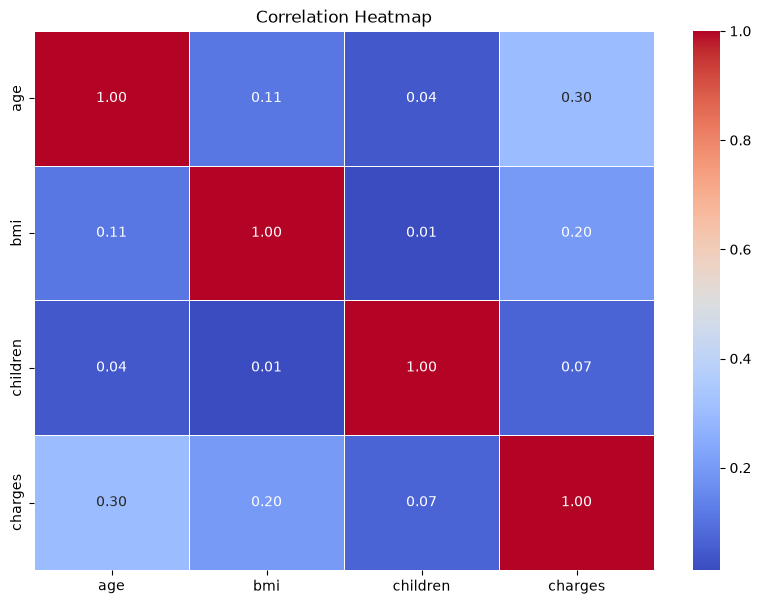

In [28]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')

plt.show()

In [29]:
charges_corr = corr['charges'].sort_values(ascending=False)

print(charges_corr)

charges     1.000000
age         0.299008
bmi         0.198341
children    0.067998
Name: charges, dtype: float64


In [30]:
smoker_analysis = df.groupby('smoker')['charges'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

smoker_analysis

,count,mean,median,min,max
smoker,,,,,
no,1064,8434.268298,7345.40530,1121.8739,36910.60803
yes,274,32050.231832,34456.34845,12829.4551,63770.42801


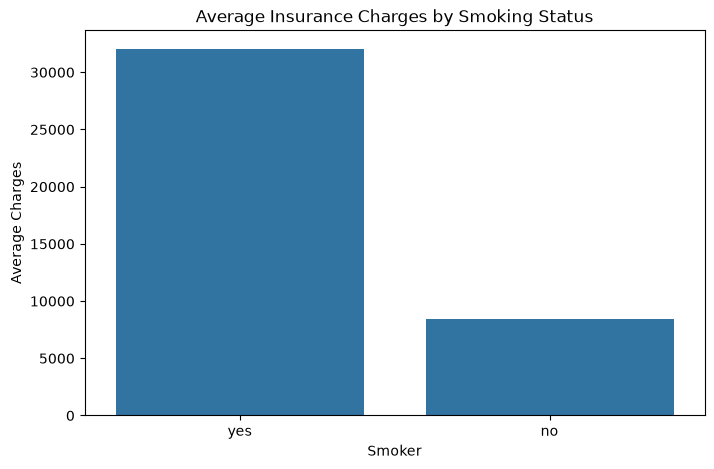

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='smoker',
    y='charges',
    estimator='mean',
    errorbar=None
)

plt.title('Average Insurance Charges by Smoking Status')
plt.xlabel('Smoker')
plt.ylabel('Average Charges')

plt.show()

EDA CONCLUSION

1. The dataset contains numerical and categorical variables.

2. The target variable for prediction is charges.

3. The distribution of charges was examined using a histogram
   and boxplot.

4. The relationship between age, BMI, children and charges
   was examined.

5. The effect of smoking status, gender and region on
   insurance charges was analyzed.

6. Correlation analysis was performed to identify linear
   relationships between numerical features and charges.

7. Potential outliers and skewness will be investigated
   further during data preprocessing.